# Guide secondary-edge samples

Compare secondary-edge gradients before and after building an importance-sampling distribution. Guiding changes the Monte Carlo samples, so the two noisy estimates need not match pixel by pixel.

Use the environment described in [README](README.md). Run all cells in order.
Defaults use modest resolution/sample counts for interactive GPU execution; increase them for smoother estimates.


In [1]:
import psdr_jit as psdr
import drjit
from drjit.cuda.ad import Float as FloatD, Matrix4f as Matrix4fD
from drjit.cuda import Int as IntC, Matrix4f as Matrix4fC
import numpy as np
import matplotlib.pyplot as plt
from image_util import DATA_DIR, to_image, to_srgb

assert drjit.has_backend(drjit.JitBackend.CUDA), "An NVIDIA GPU/driver is required."
# Keep bounds and other JIT checks active while learning/debugging.
drjit.set_flag(drjit.JitFlag.Debug, True)
SEED = 42

jitc_llvm_init(): LLVM API initialization failed ..


In [2]:
sc = psdr.Scene()
sc.opts.log_level = 0
sc.opts.spp = 0
sc.opts.sppe = 0
sc.opts.sppse = 4 
sc.opts.height = 128 
sc.opts.width = 128

integrator = psdr.PathTracer(1)

In [3]:
sensor = psdr.PerspectiveCamera(60, 0.000001, 10000000.)
to_world = Matrix4fD([[1.,0.,0.,278.],
                     [0.,1.,0.,273.],
                     [0.,0.,1.,-500.],
                     [0.,0.,0.,1.],])
sensor.to_world = to_world
sc.add_Sensor(sensor)

In [4]:
mybsdf1 = psdr.DiffuseBSDF([0.2, 0.9, 0.9])
sc.add_BSDF(mybsdf1, "sphere_large")

mybsdf2 = psdr.DiffuseBSDF([0.5, 0.5, 0.5])
sc.add_BSDF(mybsdf2, "back")

mybsdf3 = psdr.DiffuseBSDF([0.5, 0.5, 0.5])
sc.add_BSDF(mybsdf3, "light")

mybsdf4 = psdr.DiffuseBSDF([0.9, 0.6, 0.1])
sc.add_BSDF(mybsdf4, "sphere_small")

mybsdf5 = psdr.DiffuseBSDF([0.95, 0.95, 0.95])
sc.add_BSDF(mybsdf5, "white")

mybsdf6 = psdr.DiffuseBSDF([0.2, 0.9, 0.2])
sc.add_BSDF(mybsdf6, "green")

mybsdf7 = psdr.DiffuseBSDF([0.9, 0.2, 0.2])
sc.add_BSDF(mybsdf7, "red")

In [5]:
sc.add_Mesh(str(DATA_DIR / "cbox/cbox_luminaire.obj"), Matrix4fC([[1.,0.,0.,0.],[0.,1.,0.,-0.5],[0.,0.,1.,0.],[0.,0.,0.,1.]]), "light", psdr.AreaLight([20.0, 20.0, 8.0]))
sc.add_Mesh(str(DATA_DIR / "cbox/cbox_smallball.obj"), Matrix4fC([[1.,0.,0.,0.],[0.,1.,0.,0.],[0.,0.,1.,0.],[0.,0.,0.,1.]]), "sphere_small", None)
sc.add_Mesh(str(DATA_DIR / "cbox/cbox_largeball.obj"), Matrix4fC([[1.,0.,0.,0.],[0.,1.,0.,0.],[0.,0.,1.,0],[0.,0.,0.,1.]]), "sphere_large", None)
sc.add_Mesh(str(DATA_DIR / "cbox/cbox_floor.obj"), Matrix4fC([[1.,0.,0.,0.],[0.,1.,0.,0.],[0.,0.,1.,0.],[0.,0.,0.,1.]]), "white", None)
sc.add_Mesh(str(DATA_DIR / "cbox/cbox_ceiling.obj"), Matrix4fC([[1.,0.,0.,0.],[0.,1.,0.,0.],[0.,0.,1.,0.],[0.,0.,0.,1.]]), "white", None)
sc.add_Mesh(str(DATA_DIR / "cbox/cbox_back.obj"), Matrix4fC([[1.,0.,0.,0.],[0.,1.,0.,0.],[0.,0.,1.,0.],[0.,0.,0.,1.]]), "back", None)
sc.add_Mesh(str(DATA_DIR / "cbox/cbox_greenwall.obj"), Matrix4fC([[1.,0.,0.,0.],[0.,1.,0.,0.],[0.,0.,1.,0.],[0.,0.,0.,1.]]), "green", None)
sc.add_Mesh(str(DATA_DIR / "cbox/cbox_redwall.obj"), Matrix4fC([[1.,0.,0.,0.],[0.,1.,0.,0.],[0.,0.,1.,0.],[0.,0.,0.,1.]]), "red", None)

with drjit.suspend_grad():
    sc.configure()

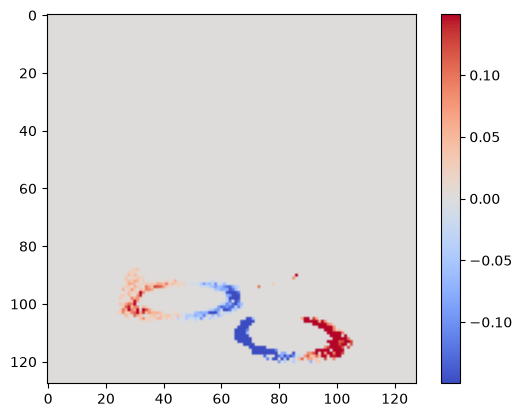

In [6]:
P = FloatD(0.) 
drjit.enable_grad(P) 

sc.param_map["Mesh[0]"].set_transform(Matrix4fD([[1.,0.,0.,P*100],[0.,1.,0.,0.],[0.,0.,1.,0.],[0.,0.,0.,1.],]))
sc.param_map["Mesh[1]"].set_transform(Matrix4fD([[1.,0.,0.,P*100],[0.,1.,0.,0.],[0.,0.,1.,0.],[0.,0.,0.,1.],]))
sc.configure([0])

img = integrator.renderD(sc, 0, seed=SEED)
drjit.forward(P)
diff_img = drjit.grad(img)
diff_img = to_image(diff_img, sc.opts.height, sc.opts.width).mean(axis=2)
assert np.isfinite(diff_img).all()
assert np.max(np.abs(diff_img)) > 0, "Expected a nonzero geometry derivative."
limit = np.quantile(np.abs(diff_img), .99) or np.max(np.abs(diff_img))
plt.imshow(diff_img, vmin=-limit, vmax=limit, cmap="coolwarm")
plt.colorbar()

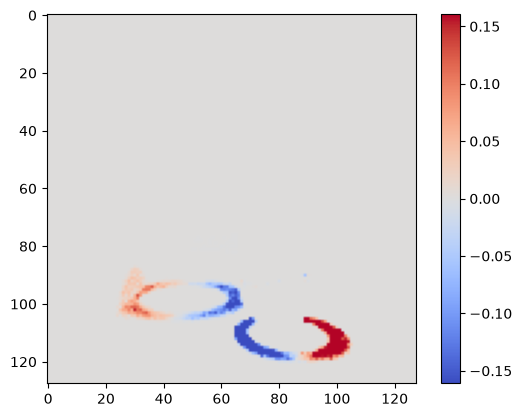

In [7]:
P = FloatD(0.) 
drjit.enable_grad(P) 

sc.param_map["Mesh[0]"].set_transform(Matrix4fD([[1.,0.,0.,P*100],[0.,1.,0.,0.],[0.,0.,1.,0.],[0.,0.,0.,1.],]))
sc.param_map["Mesh[1]"].set_transform(Matrix4fD([[1.,0.,0.,P*100],[0.,1.,0.,0.],[0.,0.,1.,0.],[0.,0.,0.,1.],]))
sc.configure([0])
integrator.preprocess_secondary_edges(sc, 0, [256, 4, 4, 8], 2, seed=SEED)

img = integrator.renderD(sc, 0, seed=SEED)
drjit.forward(P)
diff_img = drjit.grad(img)
diff_img = to_image(diff_img, sc.opts.height, sc.opts.width).mean(axis=2)
assert np.isfinite(diff_img).all()
assert np.max(np.abs(diff_img)) > 0, "Expected a nonzero geometry derivative."
limit = np.quantile(np.abs(diff_img), .99) or np.max(np.abs(diff_img))
plt.imshow(diff_img, vmin=-limit, vmax=limit, cmap="coolwarm")
plt.colorbar()